# 1. Import Libraries and Load the Dataset

In [1]:

# Import required libraries
import pandas as pd
import numpy as np
from pathlib import Path

# Dataset path
DATA_PATH = Path(
    r"E:\UPI_Fraud_Detection\data\upi_transactions_synthetic_enhanced_final.csv"
)

# Check whether the dataset exists
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

# Load the original dataset
df = pd.read_csv(DATA_PATH, low_memory=False)

# Display basic loading information
print("Dataset loaded successfully!")
print(f"Dataset Shape: {df.shape}")
print(f"Total Records: {len(df):,}")
print(f"Total Columns: {len(df.columns)}")


Dataset loaded successfully!
Dataset Shape: (100000, 43)
Total Records: 100,000
Total Columns: 43


# 2. Verify Target Distribution and Dataset Integrity

In [2]:
# Verify target column
TARGET = "is_fraud"

if TARGET not in df.columns:
    raise ValueError(f"Target column'{TARGET}' not found.")

print("Target Class Distribution")
print((df[TARGET].value_counts(normalize=True).sort_index() * 100).round(2))

print("\nTotal Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Tranaction IDs:", df["transaction_id"].duplicated().sum())

print("\nunique Target Values:", sorted(df[TARGET].dropna().unique()))

Target Class Distribution
is_fraud
0    99.0
1     1.0
Name: proportion, dtype: float64

Total Missing Values: 0
Duplicate Rows: 0
Duplicate Tranaction IDs: 0

unique Target Values: [np.int64(0), np.int64(1)]


# 3. Define Features and Target Variable

In [3]:
EXCLUDED_COLUMNS = [
    "transaction_id",
    "timestamp",
    "user_id",
    "device_id",
    "payee_id",
    "is_fraud"
]


X_xgb = df.drop(columns=EXCLUDED_COLUMNS).copy()
y_xgb = df["is_fraud"].copy()


print("Feature Matrix Shape:", X_xgb.shape)
print("Target Vector Shape:", y_xgb.shape)

print("\nNumber of Features:", X_xgb.shape[1])
print("Target Distribution:")
print(y_xgb.value_counts().sort_index())


Feature Matrix Shape: (100000, 37)
Target Vector Shape: (100000,)

Number of Features: 37
Target Distribution:
is_fraud
0    99000
1     1000
Name: count, dtype: int64


# 4. Split Dataset into Training, Validation and Testing Sets

In [4]:
from sklearn.model_selection import train_test_split

X_train_pool, X_test_xgb, y_train_pool, y_test_xgb = train_test_split(
    X_xgb,
    y_xgb,
    test_size=0.20,
    random_state=42,
    stratify=y_xgb
)

X_train_xgb, X_val_xgb, y_train_xgb, y_val_xgb = train_test_split(
    X_train_pool,
    y_train_pool,
    test_size=0.20,
    random_state=42,
    stratify=y_train_pool
)

print("Training Set:", X_train_xgb.shape)
print("Validation Set:", X_val_xgb.shape)
print("Testing Set:", X_test_xgb.shape)
print("\nFraud distribution:")
print("Training:\n", y_train_xgb.value_counts().sort_index())
print("Validation:\n", y_val_xgb.value_counts().sort_index())
print("Testing:\n", y_test_xgb.value_counts().sort_index())

Training Set: (64000, 37)
Validation Set: (16000, 37)
Testing Set: (20000, 37)

Fraud distribution:
Training:
 is_fraud
0    63360
1      640
Name: count, dtype: int64
Validation:
 is_fraud
0    15840
1      160
Name: count, dtype: int64
Testing:
 is_fraud
0    19800
1      200
Name: count, dtype: int64


# 5. Identify Numerical and Categorical Features

In [5]:
CATEGORICAL_FEATURES = X_train_xgb.select_dtypes(
    include=["object", "category"]
).columns.tolist()

NUMERICAL_FEATURES = X_train_xgb.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Categorical Features:", len(CATEGORICAL_FEATURES))
print(CATEGORICAL_FEATURES)

print("\nNumerical Features:", len(NUMERICAL_FEATURES))
print(NUMERICAL_FEATURES)

print("\nTotal Features:", len(CATEGORICAL_FEATURES) + len(NUMERICAL_FEATURES))

Categorical Features: 8
['payee_type', 'merchant_category', 'transaction_type', 'festival_name', 'sale_campaign', 'offer_type', 'disruption_type', 'location_context']

Numerical Features: 29
['amount_inr', 'transaction_latitude', 'transaction_longitude', 'distance_from_home_km', 'hour_of_day', 'day_of_week', 'is_weekend', 'is_night', 'is_new_device', 'is_new_payee', 'payee_account_age_days', 'txns_last_1h', 'txns_last_24h', 'distinct_payees_last_24h', 'minutes_since_last_txn', 'historical_avg_amount', 'amount_to_avg_ratio', 'balance_before_inr', 'balance_drain_ratio', 'is_festival_period', 'is_sale_day', 'is_payday_period', 'is_offer_exposed', 'is_power_outage', 'is_network_disruption', 'retry_count', 'payment_attempt_count', 'is_payment_retry', 'is_traveling']

Total Features: 37


# 6. Build and Apply the Preprocessing Pipeline

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Create preprocessing pipeline
preprocessor_xgb = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            CATEGORICAL_FEATURES
        ),
        (
            "numerical",
            "passthrough",
            NUMERICAL_FEATURES
        )
    ]
)

# Fit the preprocessor using training data only
X_train_processed = preprocessor_xgb.fit_transform(X_train_xgb)

# Transform validation and testing data
X_val_processed = preprocessor_xgb.transform(X_val_xgb)
X_test_processed = preprocessor_xgb.transform(X_test_xgb)

# Display processed dataset dimensions
print("Training Processed Shape:", X_train_processed.shape)
print("Validation Processed Shape:", X_val_processed.shape)
print("Testing Processed Shape:", X_test_processed.shape)

print("\nPreprocessing completed successfully!")

Training Processed Shape: (64000, 69)
Validation Processed Shape: (16000, 69)
Testing Processed Shape: (20000, 69)

Preprocessing completed successfully!


# 7. Calculate Class imbalance Weight

In [7]:
negative_count = (y_train_xgb == 0).sum()
positive_count = (y_train_xgb == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Genuine Transactions:", negative_count)
print("Fraudulent Transaction:", positive_count)
print("Scale Positive Weight:", scale_pos_weight)

Genuine Transactions: 63360
Fraudulent Transaction: 640
Scale Positive Weight: 99.0


# 8. Configure the XGBoost Classifier

In [8]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [9]:
import xgboost as xgb
from xgboost import XGBClassifier

print("XGBoost Version:", xgb.__version__)
print("XGBoost imported successfully")

XGBoost Version: 3.4.1
XGBoost imported successfully


In [10]:
xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

print("XGBoost Classifier configured successfully")
print(xgb_model)

XGBoost Classifier configured successfully
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=500,
              n_jobs=-1, num_parallel_tree=None, ...)


# 9. Train the XGBoost Model

In [11]:
import time
start_time = time.time()

xgb_model.fit(
    X_train_processed,
    y_train_xgb,
    eval_set=[(X_val_processed, y_val_xgb)],
    verbose=50
)

training_time = time.time() - start_time

print("\nXGBoost Training Completed Successfully")
print(f"Training Time: {training_time:.2f} seconds")
print(f"Trees Trained: {xgb_model.n_estimators}")

[0]	validation_0-logloss:0.65380
[50]	validation_0-logloss:0.14508
[100]	validation_0-logloss:0.08953
[150]	validation_0-logloss:0.06547
[200]	validation_0-logloss:0.05057
[250]	validation_0-logloss:0.04223
[300]	validation_0-logloss:0.03625
[350]	validation_0-logloss:0.03179
[400]	validation_0-logloss:0.02886
[450]	validation_0-logloss:0.02648
[499]	validation_0-logloss:0.02528

XGBoost Training Completed Successfully
Training Time: 4.55 seconds
Trees Trained: 500


# 10. Evaluate XGBoost on Validation Data

In [12]:
from sklearn.metrics import (
classification_report,
confusion_matrix,
roc_auc_score,
average_precision_score,
log_loss
)

# Generate Validation Probabilities
y_val_prob = xgb_model.predict_proba(X_val_processed)[:,1]

y_val_pred = (y_val_prob >= 0.5).astype(int)

print("VALIDATION CLASSIFICATION REPORT")
print(classification_report(y_val_xgb, y_val_pred, digits=4))

print("CONFUSION MATRIX")
print(confusion_matrix(y_val_xgb, y_val_pred))

VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9967    0.9950    0.9959     15840
           1     0.5775    0.6750    0.6225       160

    accuracy                         0.9918     16000
   macro avg     0.7871    0.8350    0.8092     16000
weighted avg     0.9925    0.9918    0.9921     16000

CONFUSION MATRIX
[[15761    79]
 [   52   108]]


# 11. Tune Classification Threshold Using Validation Data

In [14]:
from sklearn.metrics import precision_recall_curve

# Calculate precision and recall at different thresholds
precisions, recalls, thresholds = precision_recall_curve(
    y_val_xgb,
    y_val_prob
)

# Calculate F1-score for each threshold
f1_scores = (
    2 * precisions[:-1] * recalls[:-1]
    / (precisions[:-1] + recalls[:-1] + 1e-10)
)

# Identify threshold with the highest F1-score
best_index = np.argmax(f1_scores)

best_threshold_xgb = thresholds[best_index]
best_f1_xgb = f1_scores[best_index]

print("Best Validation Threshold:", round(best_threshold_xgb, 4))
print("Best Validation F1-Score:", round(best_f1_xgb, 4))
print("Precision at Best Threshold:", round(precisions[best_index], 4))
print("Recall at Best Threshold:", round(recalls[best_index], 4))

Best Validation Threshold: 0.8849
Best Validation F1-Score: 0.6769
Precision at Best Threshold: 0.88
Recall at Best Threshold: 0.55


# 13. Evaluate Model Using Optimized Threshold

In [15]:
from sklearn.metrics import classification_report, confusion_matrix

# Apply optimized threshold
y_val_pred_tuned = (
    y_val_prob >= best_threshold_xgb
).astype(int)

# Classification report
print("TUNED VALIDATION CLASSIFICATION REPORT")
print(
    classification_report(
        y_val_xgb,
        y_val_pred_tuned,
        digits=4
    )
)

# Confusion matrix
print("TUNED VALIDATION CONFUSION MATRIX")
print(confusion_matrix(y_val_xgb, y_val_pred_tuned))

TUNED VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9955    0.9992    0.9974     15840
           1     0.8800    0.5500    0.6769       160

    accuracy                         0.9948     16000
   macro avg     0.9377    0.7746    0.8371     16000
weighted avg     0.9943    0.9948    0.9941     16000

TUNED VALIDATION CONFUSION MATRIX
[[15828    12]
 [   72    88]]


# 14. Compare Default and Optimized Threshold Performance

In [16]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate metrics at default threshold (0.5)
default_precision = precision_score(y_val_xgb, y_val_pred)
default_recall = recall_score(y_val_xgb, y_val_pred)
default_f1 = f1_score(y_val_xgb, y_val_pred)

# Calculate metrics at optimized threshold
tuned_precision = precision_score(y_val_xgb, y_val_pred_tuned)
tuned_recall = recall_score(y_val_xgb, y_val_pred_tuned)
tuned_f1 = f1_score(y_val_xgb, y_val_pred_tuned)

# Display comparison
threshold_comparison = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-Score"],
    "Default Threshold (0.5)": [
        default_precision,
        default_recall,
        default_f1
    ],
    "Optimized Threshold": [
        tuned_precision,
        tuned_recall,
        tuned_f1
    ]
})

print("THRESHOLD PERFORMANCE COMPARISON")
display(threshold_comparison.round(4))

THRESHOLD PERFORMANCE COMPARISON


,Metric,Default Threshold (0.5),Optimized Threshold
0,Precision,0.5775,0.8800
1,Recall,0.6750,0.5500
2,F1-Score,0.6225,0.6769


# 15. Evaluate XGBoost Using ROC-AUC and Precision-Recall AUC

In [17]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Calculate ROC-AUC
xgb_roc_auc = roc_auc_score(y_val_xgb, y_val_prob)

# Calculate Precision-Recall AUC (Average Precision)
xgb_pr_auc = average_precision_score(y_val_xgb, y_val_prob)

print("XGBOOST VALIDATION CURVE METRICS")
print(f"ROC-AUC Score: {xgb_roc_auc:.4f}")
print(f"PR-AUC Score: {xgb_pr_auc:.4f}")

XGBOOST VALIDATION CURVE METRICS
ROC-AUC Score: 0.9770
PR-AUC Score: 0.7070


# 16. Visualize the Precision-Recall Curve

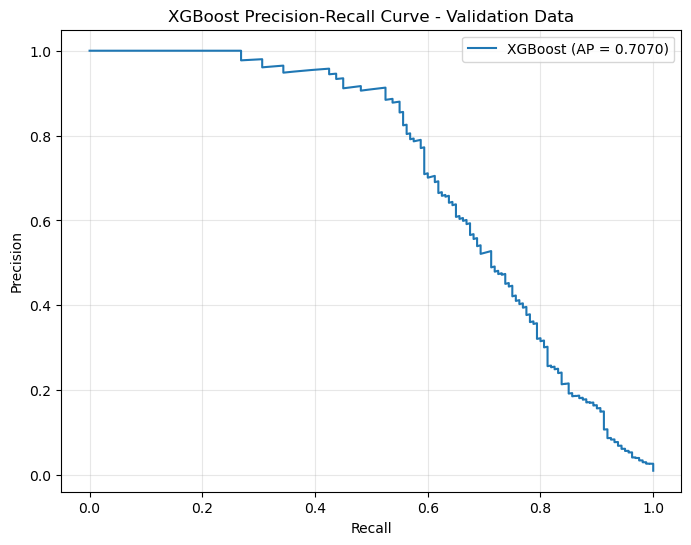

In [19]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# Calculate precision and recall at different thresholds
precisions, recalls, thresholds = precision_recall_curve(
    y_val_xgb,
    y_val_prob
)

# Plot Precision-Recall Curve
plt.figure(figsize=(8, 6))

plt.plot(
    recalls,
    precisions,
    label=f"XGBoost (AP = {xgb_pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("XGBoost Precision-Recall Curve - Validation Data")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 17. Visualize the ROC Curve

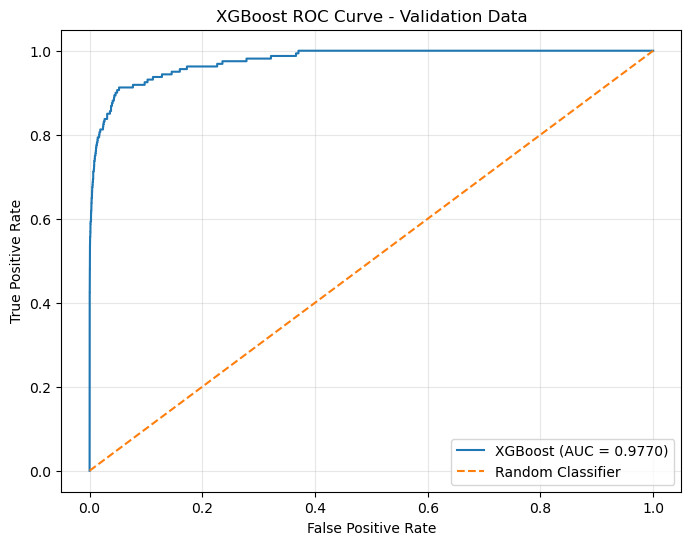

In [20]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC curve values
fpr, tpr, thresholds_roc = roc_curve(
    y_val_xgb,
    y_val_prob
)

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_val_xgb, y_val_prob)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curve - Validation Data")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 18. Analyze XGBoost Feature Importance

TOP 20 XGBOOST IMPORTANT FEATURES


,Feature,Importance
13,categorical__transaction_type_Collect_Request,0.097265
56,numerical__amount_to_avg_ratio,0.091623
49,numerical__is_new_payee,0.079177
14,categorical__transaction_type_Pay,0.063459
48,numerical__is_new_device,0.049794
30,categorical__offer_type_Festival Offer,0.034774
25,categorical__sale_campaign_Mid-Year Sale,0.031451
51,numerical__txns_last_1h,0.028785
36,categorical__disruption_type_Power + Network,0.027511
24,categorical__sale_campaign_Ganesh Chaturthi Sale,0.023858


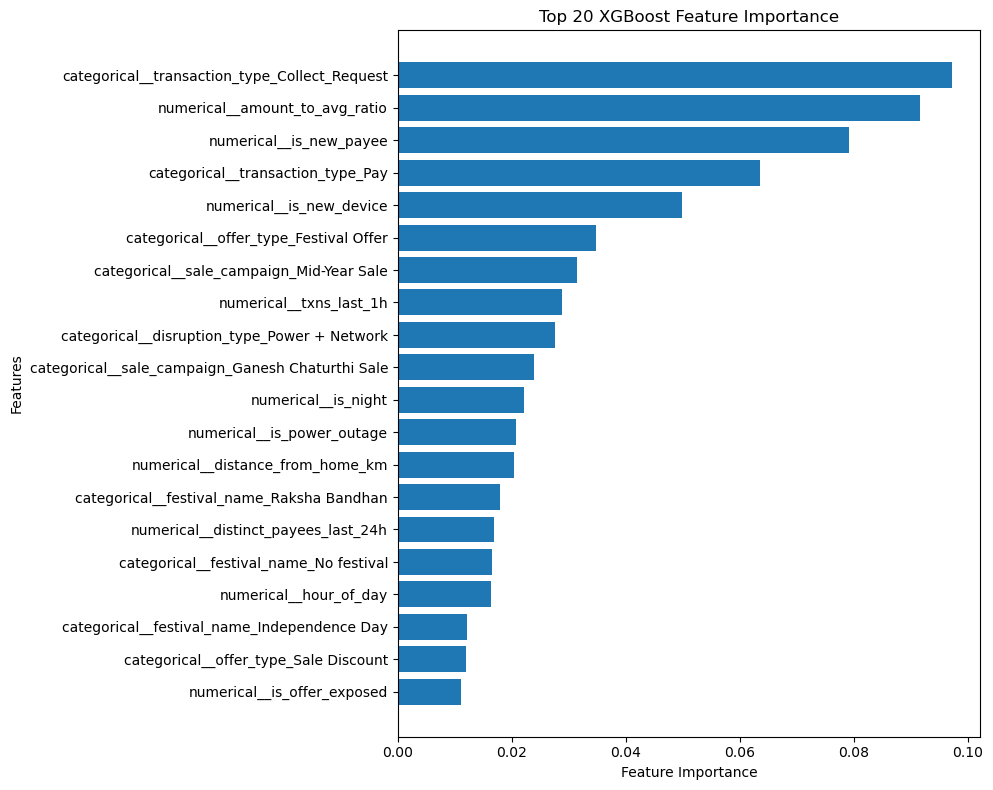

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = preprocessor_xgb.get_feature_names_out()

# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20 important features
print("TOP 20 XGBOOST IMPORTANT FEATURES")
display(feature_importance.head(20))

# Plot feature importance
plt.figure(figsize=(10, 8))

top_features = feature_importance.head(20).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 20 XGBoost Feature Importance")

plt.tight_layout()
plt.show()

# 19. Save XGBoost Model Artifacts

In [22]:
import joblib
import os

# Create a separate directory for XGBoost artifacts
os.makedirs("xgboost_artifacts", exist_ok=True)

# Save trained XGBoost model
joblib.dump(
    xgb_model,
    "xgboost_artifacts/xgboost_model.pkl"
)

# Save preprocessing pipeline
joblib.dump(
    preprocessor_xgb,
    "xgboost_artifacts/xgboost_preprocessor.pkl"
)

# Save optimized classification threshold
joblib.dump(
    best_threshold_xgb,
    "xgboost_artifacts/xgboost_threshold.pkl"
)

# Save original feature column names
joblib.dump(
    X_xgb.columns.tolist(),
    "xgboost_artifacts/xgboost_feature_columns.pkl"
)

print("XGBoost artifacts saved successfully!")

print("\nSaved Files:")
for file in os.listdir("xgboost_artifacts"):
    print(file)

XGBoost artifacts saved successfully!

Saved Files:
xgboost_feature_columns.pkl
xgboost_model.pkl
xgboost_preprocessor.pkl
xgboost_threshold.pkl
xgboost_validation_results.csv


# 20. Load and Verify Saved XGBoost Artifacts

In [2]:
import joblib
import os

# Define artifact directory
artifact_dir = "xgboost_artifacts"

# Load saved artifacts
loaded_xgb_model = joblib.load(
    os.path.join(artifact_dir, "xgboost_model.pkl")
)

loaded_xgb_preprocessor = joblib.load(
    os.path.join(artifact_dir, "xgboost_preprocessor.pkl")
)

loaded_xgb_threshold = joblib.load(
    os.path.join(artifact_dir, "xgboost_threshold.pkl")
)

loaded_xgb_features = joblib.load(
    os.path.join(artifact_dir, "xgboost_feature_columns.pkl")
)

# Verify loaded artifacts
print("XGBoost Artifacts Loaded Successfully!")
print("Model:", type(loaded_xgb_model).__name__)
print("Preprocessor:", type(loaded_xgb_preprocessor).__name__)
print("Optimized Threshold:", loaded_xgb_threshold)
print("Number of Original Features:", len(loaded_xgb_features))

XGBoost Artifacts Loaded Successfully!
Model: XGBClassifier
Preprocessor: ColumnTransformer
Optimized Threshold: 0.8848697
Number of Original Features: 37


# 21. Final Testing on Unseen Test DataSet

In [24]:
from sklearn.metrics import(
classification_report,
confusion_matrix,
roc_auc_score,
average_precision_score
)

y_test_prob_xgb = loaded_xgb_model.predict_proba(
    X_test_processed
)[:,1]

y_test_pred_xgb = (
    y_test_prob_xgb >= loaded_xgb_threshold
).astype(int)

print("XGBOOST FINAL TEST CLASSIFICATION REPORT")

print(
    classification_report(
        y_test_xgb,
        y_test_pred_xgb,
        digits=4
    )
)

print("\nXGBOOST FINAL TEST CONFUSION MATRIX")

print(confusion_matrix(y_test_xgb, y_test_pred_xgb))

print("\nXGBOOST FINAL TEST METRICS")
print(f"ROC-AUC: {roc_auc_score(y_test_xgb, y_test_prob_xgb):.4f}")
print(f"PR-AUC: {average_precision_score(y_test_xgb, y_test_prob_xgb):.4f}")

XGBOOST FINAL TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9953    0.9992    0.9973     19800
           1     0.8699    0.5350    0.6625       200

    accuracy                         0.9946     20000
   macro avg     0.9326    0.7671    0.8299     20000
weighted avg     0.9941    0.9946    0.9939     20000


XGBOOST FINAL TEST CONFUSION MATRIX
[[19784    16]
 [   93   107]]

XGBOOST FINAL TEST METRICS
ROC-AUC: 0.9614
PR-AUC: 0.6884


# 22. Save XGBoost Final Test Evaluation Results

In [25]:
# Store final test evaluation metrics
xgb_test_results = pd.DataFrame({
    "Model": ["XGBoost"],
    "Accuracy": [
        (y_test_pred_xgb == y_test_xgb).mean()
    ],
    "Precision": [
        precision_score(y_test_xgb, y_test_pred_xgb)
    ],
    "Recall": [
        recall_score(y_test_xgb, y_test_pred_xgb)
    ],
    "F1_Score": [
        f1_score(y_test_xgb, y_test_pred_xgb)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test_xgb, y_test_prob_xgb)
    ],
    "PR_AUC": [
        average_precision_score(y_test_xgb, y_test_prob_xgb)
    ]
})

# Save evaluation results
xgb_test_results.to_csv(
    "xgboost_artifacts/xgboost_evaluation_results.csv",
    index=False
)

print("XGBoost final test results saved successfully!")
display(xgb_test_results.round(4))

XGBoost final test results saved successfully!


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,XGBoost,0.9946,0.8699,0.535,0.6625,0.9614,0.6884


# 23. Save XGBoost Final Test Predictions

# Create final test prediction DataFrame
xgb_test_predictions = pd.DataFrame({
    "Actual_Fraud": y_test_xgb.values,
    "Fraud_Probability": y_test_prob_xgb,
    "Predicted_Fraud": y_test_pred_xgb
})

# Save predictions
xgb_test_predictions.to_csv(
    "xgboost_artifacts/xgboost_test_predictions.csv",
    index=False
)

print("XGBoost test predictions saved successfully!")
print("Total Records:", len(xgb_test_predictions))

display(xgb_test_predictions.head())

# 24. Final XGBoost Model Summary

In [27]:
print("=" * 55)
print("          FINAL XGBOOST MODEL SUMMARY")
print("=" * 55)

print("\nMODEL CONFIGURATION")
print(f"Algorithm: XGBoost Classifier")
print(f"Number of Trees: {loaded_xgb_model.n_estimators}")
print(f"Maximum Tree Depth: {loaded_xgb_model.max_depth}")
print(f"Learning Rate: {loaded_xgb_model.learning_rate}")
print(f"Class Weight: {scale_pos_weight}")

print("\nDATASET")
print(f"Training Records: {len(X_train_xgb)}")
print(f"Validation Records: {len(X_val_xgb)}")
print(f"Testing Records: {len(X_test_xgb)}")

print("\nOPTIMIZED THRESHOLD")
print(f"Threshold: {loaded_xgb_threshold:.4f}")

print("\nFINAL TEST PERFORMANCE")
display(xgb_test_results.round(4))

print("=" * 55)

          FINAL XGBOOST MODEL SUMMARY

MODEL CONFIGURATION
Algorithm: XGBoost Classifier
Number of Trees: 500
Maximum Tree Depth: 6
Learning Rate: 0.05
Class Weight: 99.0

DATASET
Training Records: 64000
Validation Records: 16000
Testing Records: 20000

OPTIMIZED THRESHOLD
Threshold: 0.8849

FINAL TEST PERFORMANCE


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,XGBoost,0.9946,0.8699,0.535,0.6625,0.9614,0.6884


# 25. Verify XGBoost Artifact Directory and Saved Files

In [28]:
import os

artifact_dir = "xgboost_artifacts"

print("XGBoost Artifact Directory Verification")
print("=" * 45)

if os.path.exists(artifact_dir):
    files = os.listdir(artifact_dir)

    for file in sorted(files):
        file_path = os.path.join(artifact_dir, file)

        if os.path.isfile(file_path):
            print(f"✓ {file}")

    print("\nTotal Files:", len(files))
else:
    print("XGBoost artifact directory not found.")

XGBoost Artifact Directory Verification
✓ xgboost_evaluation_results.csv
✓ xgboost_feature_columns.pkl
✓ xgboost_model.pkl
✓ xgboost_preprocessor.pkl
✓ xgboost_test_predictions.csv
✓ xgboost_threshold.pkl
✓ xgboost_validation_results.csv

Total Files: 7


## Heading 21 – XGBoost Artifact Verification and Sample Prediction Testing
This provides a useful demonstration that both saved models can be loaded and used without retraining.

XGBOOST ARTIFACT VERIFICATION

All four artifacts loaded successfully.

Model: XGBClassifier
Preprocessor: ColumnTransformer
Features: 37
Threshold: 0.8848697
Processed Shape: (10, 69)

Sample Predictions:
Transaction 1: 0.0075 - Genuine
Transaction 2: 0.0918 - Genuine
Transaction 3: 0.0018 - Genuine
Transaction 4: 0.0001 - Genuine
Transaction 5: 0.0009 - Genuine
Transaction 6: 0.0000 - Genuine
Transaction 7: 0.0006 - Genuine
Transaction 8: 0.0002 - Genuine
Transaction 9: 0.0016 - Genuine
Transaction 10: 0.0004 - Genuine


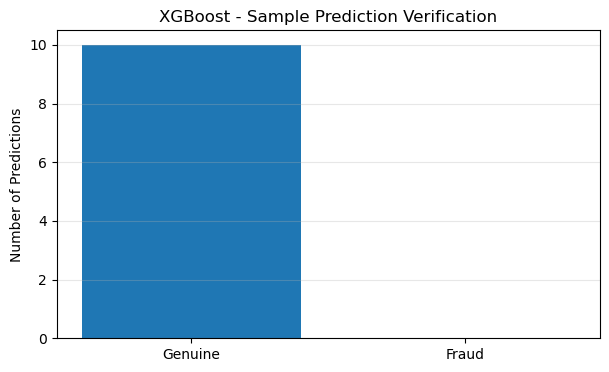


XGBOOST INFERENCE TEST COMPLETED SUCCESSFULLY


In [3]:

import matplotlib.pyplot as plt
import numpy as np

print("=" * 55)
print("XGBOOST ARTIFACT VERIFICATION")
print("=" * 55)

# 1. Verify all four artifacts
assert loaded_xgb_model is not None
assert loaded_xgb_preprocessor is not None
assert loaded_xgb_threshold is not None
assert len(loaded_xgb_features) == 37

print("\nAll four artifacts loaded successfully.")

# 2. Prepare 10 sample transactions
sample_data = df[loaded_xgb_features].head(10).copy()

# 3. Apply the saved preprocessing pipeline
sample_processed = loaded_xgb_preprocessor.transform(sample_data)

# 4. Generate fraud probabilities
probabilities = loaded_xgb_model.predict_proba(
    sample_processed
)[:, 1]

# 5. Apply the saved threshold
predictions = (
    probabilities >= loaded_xgb_threshold
).astype(int)

print("\nModel:", type(loaded_xgb_model).__name__)
print("Preprocessor:", type(loaded_xgb_preprocessor).__name__)
print("Features:", len(loaded_xgb_features))
print("Threshold:", loaded_xgb_threshold)
print("Processed Shape:", sample_processed.shape)

# 6. Display sample predictions
results = np.column_stack((probabilities, predictions))

print("\nSample Predictions:")
for i, (prob, pred) in enumerate(results, start=1):
    label = "Fraud" if pred == 1 else "Genuine"
    print(f"Transaction {i}: {prob:.4f} - {label}")

# 7. Plot prediction results
genuine = np.sum(predictions == 0)
fraud = np.sum(predictions == 1)

plt.figure(figsize=(7, 4))
plt.bar(["Genuine", "Fraud"], [genuine, fraud])
plt.title("XGBoost - Sample Prediction Verification")
plt.ylabel("Number of Predictions")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("\nXGBOOST INFERENCE TEST COMPLETED SUCCESSFULLY")
